# Questions 4.1 to 4.8

### Imports

In [1]:
import config as cfg
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import src.loading as ld
import src.features as ftrs
import src.normalise as norm
import src.evaluation as evl
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedShuffleSplit, LeaveOneGroupOut, GroupKFold, StratifiedKFold
from sklearn.metrics import ConfusionMatrixDisplay, recall_score, classification_report
from scipy.stats import wilcoxon

### Loading DataSet (Dev Set Only)

In [2]:
df = ld.load_frames()

### Normalising Data

In [3]:
df_n = norm.normalise_d(df)

### Feature Table & Extracting Values

In [4]:
feature_table = ftrs.build_feature_table(df_n)
feature_table_base = ftrs.build_feature_table(df_n, own=False)

In [5]:
feature_names = feature_table.columns.tolist()
X = feature_table.to_numpy()
y = feature_table.index.get_level_values("emotion").to_numpy()
groups = feature_table.index.get_level_values("actor").to_numpy()

labels_names = [cfg.EMOTIONS[k] for k in cfg.EMOTIONS]

In [6]:
print("Feature Table Shape:", feature_table.shape)
print("Number of unique actors:", len(np.unique(groups)))
print("Number of unique emotions:", len(np.unique(y)))
print("Number of samples per emotion:")
print(feature_table.groupby("emotion").size())

Feature Table Shape: (1200, 55)
Number of unique actors: 20
Number of unique emotions: 8
Number of samples per emotion:
emotion
1     80
2    160
3    160
4    160
5    160
6    160
7    160
8    160
dtype: int64


## 4.1 Random protocol

In [7]:
cv_shuffle = StratifiedShuffleSplit(n_splits=30, test_size=0.3, random_state=cfg.SEED)
pipe_shuffle = Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf'))])

per_fold_results_shuffle, predictions_shuffle, conf_matrix_shuffle = evl.evaluation(X, y, cv_shuffle, pipe_shuffle)

### Mean & SD of Accuracy and Macro F1

In [8]:
results_shuffle = per_fold_results_shuffle[["accuracy", "macro_f1"]].agg(["mean", "std"])
results_shuffle

,accuracy,macro_f1
mean,0.753796,0.752333
std,0.023383,0.022934


### Confusion Matrix

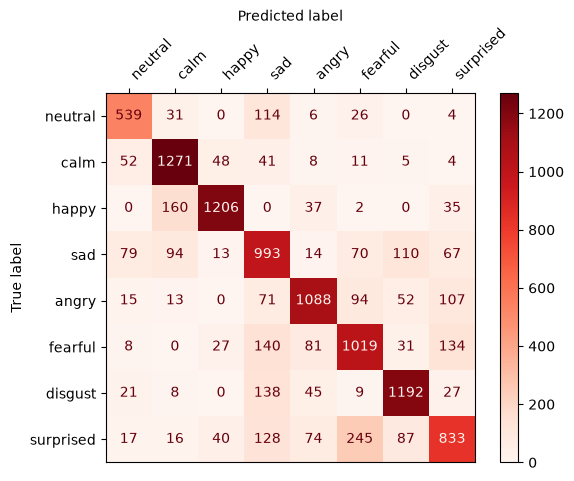

In [9]:
matrix_shuffle = ConfusionMatrixDisplay(confusion_matrix=conf_matrix_shuffle, display_labels=labels_names)
matrix_shuffle.plot(cmap=plt.cm.Reds)

ax = matrix_shuffle.ax_
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top") 
ax.set_xticklabels(labels_names, rotation=45, ha="left")
plt.show()

### Conclusions
Over 30 stratified 70/30 splits, the pipeline reaches an accuracy of 0.754 with 0.023 std and a macro F1 of 0.752 with 0.023 std. The confusion matrix is summed over the 30 repetitions, the neutral row has half the counts of the others because neutral has 80 videos instead of 160. Macro F1 still gives it the same weight as every other class.

## 4.2 LOSO protocol

In [10]:
pipe_group = Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf'))])

per_fold_results_group, predictions_group, conf_matrix_group = evl.evaluation(X, y, LeaveOneGroupOut(), pipe_group, groups)

### Mean & SD of Accuracy and Macro F1

In [11]:
results_group = per_fold_results_group[["accuracy", "macro_f1"]].agg(["mean", "std"])
results_group

,accuracy,macro_f1
mean,0.589167,0.557425
std,0.126731,0.145965


### Macro F1 Score per Held-out Actor

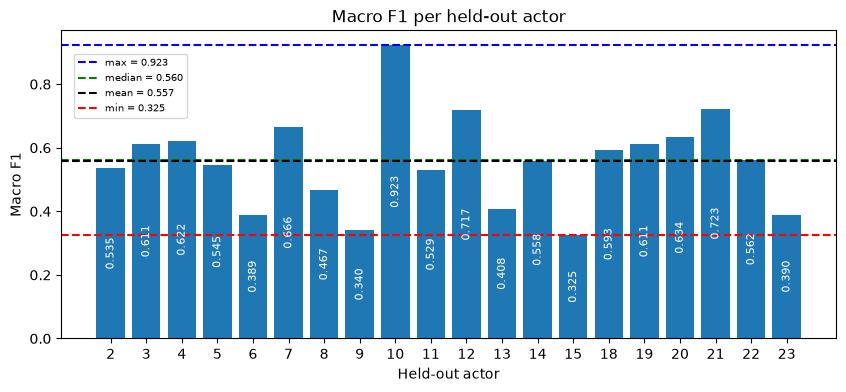

In [12]:
df_plot = per_fold_results_group.sort_values("held_out_actor")
mean_f1 = df_plot["macro_f1"].mean()
min_f1 = df_plot["macro_f1"].min()
median_f1 = df_plot["macro_f1"].median()
max_f1 = df_plot["macro_f1"].max()

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(df_plot["held_out_actor"].astype(str), df_plot["macro_f1"])
ax.bar_label(bars, fmt="%.3f", label_type="center", color="white", fontsize=8, rotation=90)
ax.axhline(max_f1, color="blue", linestyle="--", label=f"max = {max_f1:.3f}")
ax.axhline(median_f1, color="green", linestyle="--", label=f"median = {median_f1:.3f}")
ax.axhline(mean_f1, color="black", linestyle="--", label=f"mean = {mean_f1:.3f}")
ax.axhline(min_f1, color="red", linestyle="--", label=f"min = {min_f1:.3f}")
ax.set_xlabel("Held-out actor")
ax.set_ylabel("Macro F1")
ax.set_title("Macro F1 per held-out actor")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(0.01, 0.94))
plt.show()


### Confusion Matrix

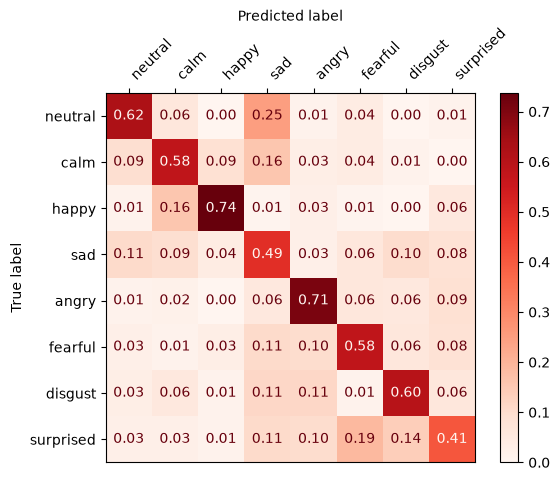

In [13]:
disp = ConfusionMatrixDisplay.from_predictions(
    predictions_group["y_true"],
    predictions_group["y_pred"],
    labels=np.unique(y),
    display_labels=labels_names,
    normalize="true",
    values_format=".2f",
    cmap=plt.cm.Reds,
)

ax = disp.ax_
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top") 
ax.set_xticklabels(labels_names, rotation=45, ha="left")
plt.show()

### Conclusions
Under LOSO, accuracy is 0.589 with 0.127 std and macro F1 is 0.557 with 0.146 std. The macro F1 per actor ranges from 0.325 (actor 15) to 0.923 (actor 10), with a median of 0.560. Actor 15 is the actor whose head bends down at the end of the videos (2.3), where the tracking is less reliable.

## 4.3 Random vs LOSO

### Confusion Matrix Comparison

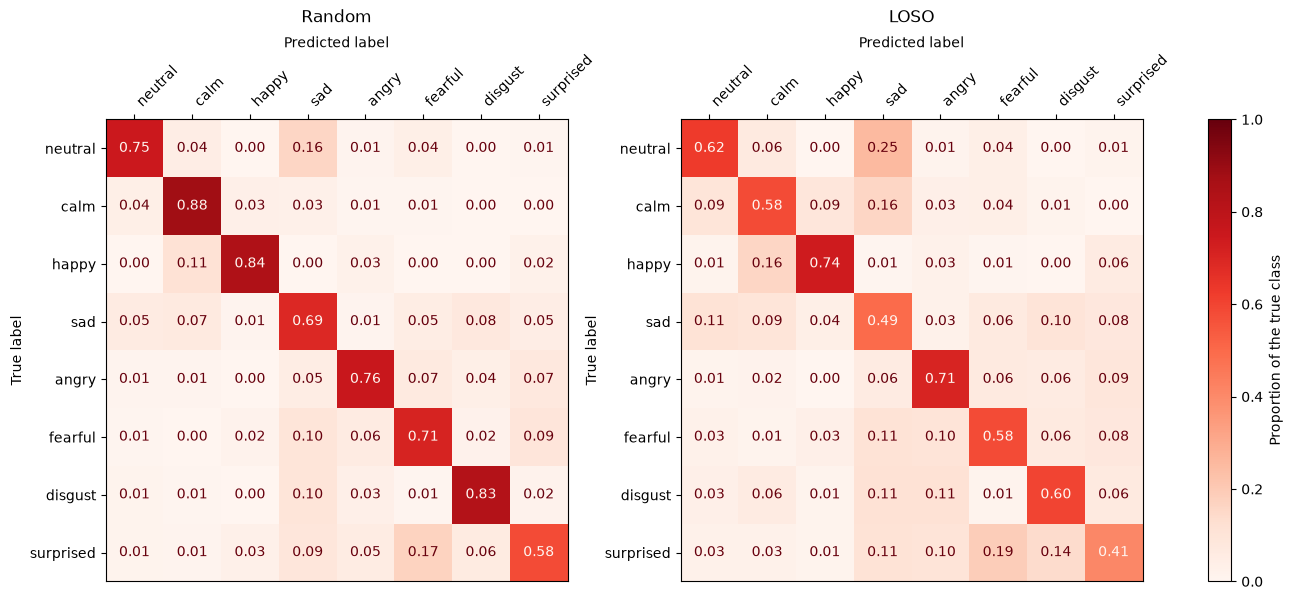

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

protocols = {"Random": predictions_shuffle,
             "LOSO": predictions_group}

for ax, (title, preds) in zip(axes, protocols.items()):
    disp = ConfusionMatrixDisplay.from_predictions(
        preds["y_true"],
        preds["y_pred"],
        labels=np.unique(y),
        display_labels=labels_names,
        normalize="true",
        values_format=".2f",
        cmap=plt.cm.Reds,
        colorbar=False,
        im_kw={"vmin": 0, "vmax": 1},
        ax=ax,
    )
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xticklabels(labels_names, rotation=45, ha="left")
    ax.set_title(title, pad=70)

fig.colorbar(disp.im_, ax=axes, label="Proportion of the true class")
plt.show()

### Comparison Table

In [15]:
protocols_table = pd.concat({"Random": results_shuffle, "LOSO": results_group}, axis=1)
protocols_table

Random                LOSO          
      accuracy  macro_f1  accuracy  macro_f1
mean  0.753796  0.752333  0.589167  0.557425
std   0.023383  0.022934  0.126731  0.145965

### Per-class Recall Comparison

In [16]:
recall_random = recall_score(predictions_shuffle["y_true"], 
                             predictions_shuffle["y_pred"],
                             labels=np.unique(y), 
                             average=None)

recall_loso = recall_score(predictions_group["y_true"], 
                           predictions_group["y_pred"],
                           labels=np.unique(y), 
                           average=None)

recall = pd.DataFrame({"Random": recall_random, 
                       "LOSO": recall_loso}, index=labels_names)

recall["Drop"] = recall["Random"] - recall["LOSO"]
recall.sort_values("LOSO").round(3)


,Random,LOSO,Drop
surprised,0.578,0.406,0.172
sad,0.690,0.494,0.196
calm,0.883,0.581,0.301
fearful,0.708,0.581,0.126
disgust,0.828,0.600,0.228
neutral,0.749,0.625,0.124
angry,0.756,0.706,0.049
happy,0.838,0.738,0.100


### Answer 4.3

The random split answers to *"how well does the model recognise a new video of a person it has already seen?"*. LOSO answers to *"how well does it recognise the expressions of a person it has never seen?"*. Only LOSO estimates the performance on a new face.

Just like 1.3 stated, one row is one video, but the 60 videos of an actor are not independent. They share the same face shape, the same resting expression and the same way of acting. In a random split each actor has about 42 videos in training and 18 in test, so the model can learn each actor's own face and style, just like their usual mouth width or brow height and use it on their test videos. This is a leak of the actor's identity, and it raises the score by about 0.2 of macro F1. Under LOSO no actor appears in both sets, so this help disappears, hence the lower performance.

The per-class recall table supports this. The largest drop is *calm* (0.88 to 0.58): calm differs from neutral only slightly, relative to the actor's own resting face, so it can be recognised only when that face has been seen. The smallest drop is *angry* (0.76 to 0.71), whose frown and lowered brows look similar in every actor.

The standard deviations also mean different things. Under the random split (0.023) the 30 test sets overlap and each contains every actor, so the std only measures how much the score changes from one resampling to the next. Under LOSO (0.146) it measures how much the score changes from one person to another, from 0.325 (actor 15) to 0.923 (actor 10). This is real uncertainty about a new user.

The rest of the project must use LOSO.

## 4.4 Confusions under LOSO

### Classification Report

In [17]:
loso_report = classification_report(predictions_group["y_true"], predictions_group["y_pred"], target_names=labels_names)
print(loso_report)

              precision    recall  f1-score   support

     neutral       0.51      0.62      0.56        80
        calm       0.60      0.58      0.59       160
       happy       0.80      0.74      0.77       160
         sad       0.42      0.49      0.46       160
       angry       0.64      0.71      0.67       160
     fearful       0.60      0.58      0.59       160
     disgust       0.62      0.60      0.61       160
   surprised       0.52      0.41      0.46       160

    accuracy                           0.59      1200
   macro avg       0.59      0.59      0.59      1200
weighted avg       0.59      0.59      0.59      1200



### True vs Predicted Count 

In [18]:
counts = pd.DataFrame({"True count": predictions_group["y_true"].map(cfg.EMOTIONS).value_counts(),
                       "Predicted count": predictions_group["y_pred"].map(cfg.EMOTIONS).value_counts(),
                       }).reindex(labels_names, fill_value=0)

counts

,True count,Predicted count
neutral,80,99
calm,160,156
happy,160,147
sad,160,186
angry,160,177
fearful,160,155
disgust,160,155
surprised,160,125


### Top Confusions Table (top 5)

In [19]:
cm_norm = pd.DataFrame(conf_matrix_group / conf_matrix_group.sum(axis=1, keepdims=True),
                       index=labels_names, 
                       columns=labels_names)

off_diag = cm_norm.where(~np.eye(len(labels_names), dtype=bool))

top_confusions = (off_diag.stack()
                          .dropna()
                          .sort_values(ascending=False)
                          .head(5)
                          .rename_axis(["True", "Predicted"])
                          .reset_index(name="Rate"))

top_confusions["Reverse rate"] = [cm_norm.loc[p, t] for t, p in zip(top_confusions["True"], top_confusions["Predicted"])]
top_confusions.round(3)

,True,Predicted,Rate,Reverse rate
0,neutral,sad,0.250,0.106
1,surprised,fearful,0.188,0.081
2,calm,sad,0.156,0.094
3,happy,calm,0.156,0.088
4,surprised,disgust,0.138,0.062


### Answer 4.4

The most frequent confusions under LOSO (top 5) are listed in the table above.

The pattern is mostly plausible given the measures of Table 2:

- **Neutral, calm and sad** are all low-movement expressions. What separates them is small: slightly downturned corners (M3) and lowered brows (M4) in sad. These differences are smaller than the differences between the resting faces of different actors, so without the actor's own neutral face to compare with they overlap. *Sad* acts as the default class for these quiet faces: it is predicted 186 times for 160 true videos and has the lowest precision (0.42).
- **Surprised predicted as fearful** both raise the brows (M4), widen the eyes (M5) and open the mouth (M1). What separates them is subtle: fear stretches the lips (M2) and draws the brows together (M6).
- **Happy predicted as calm**: when calm, a person often shows a slight smile, so it shares the smile measures (M2, M3) with happy at a lower level. Happy is still the best recognised class (F1 0.77), because a full smile is distinctive.
- **Surprised predicted as disgust** is less expected from Table 2. Table 2 does not measure the raised upper lip and the wrinkled nose of disgust (our own feature M10 targets the upper lip), and in both emotions the mouth opens. M1 measures how open the mouth is, not its shape.

These errors are not symmetric: neutral predicted as sad (0.25) is more than twice as frequent as sad predicted as neutral (0.11). The model leans towards some classes, not just mixing pairs equally.

**The hardest emotion is surprised**: it has the lowest recall (0.41) and is predicted only 125 times for 160 videos. Its videos are spread over fearful, disgust, sad and angry. By F1 it ties with sad (0.46), but for different reasons: surprised is missed, while sad is predicted too often. Possible reasons:

- Every video is speech, so the mouth measures (M1 and its velocity and energy) are dominated by talking. This hides the dropped jaw, the main mouth cue of surprise.
- Its brow and eye cues (M4, M5) are shared with fear.

Surprised was also the worst class under the random split (0.58), so the difficulty comes from the features themselves, not only from the actor being unseen.


## 4.5 The C Curve (Macro F1)

### Results Table

In [20]:
curve_rows = list()
for C in cfg.C_GRID:
    pipe_C = Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf', C=C))])
    per_fold_C, _, _ = evl.evaluation(X, y, LeaveOneGroupOut(), pipe_C, groups)
    curve_rows.append({"C": C,
                       "accuracy_mean": per_fold_C["accuracy"].mean(),
                       "macro_f1_mean": per_fold_C["macro_f1"].mean(),
                       "macro_f1_std": per_fold_C["macro_f1"].std()})

c_curve = pd.DataFrame(curve_rows).set_index("C")
c_curve["macro_f1_sem"] = c_curve["macro_f1_std"] / np.sqrt(len(np.unique(groups)))
c_curve.round(4)


,accuracy_mean,macro_f1_mean,macro_f1_std,macro_f1_sem
C,,,,
0.01,0.4617,0.3882,0.1076,0.0240
0.10,0.5008,0.4276,0.1115,0.0249
1.00,0.5892,0.5574,0.1460,0.0326
10.00,0.5700,0.5367,0.1493,0.0334
100.00,0.5658,0.5335,0.1391,0.0311
1000.00,0.5658,0.5335,0.1391,0.0311


### Ploted C Curve

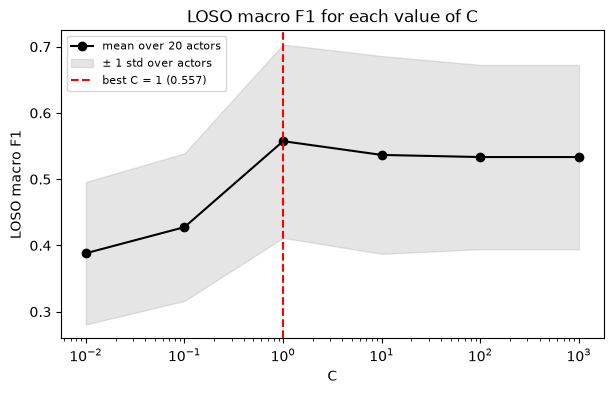

In [21]:
best_C = c_curve["macro_f1_mean"].idxmax()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(c_curve.index, c_curve["macro_f1_mean"], marker="o", color="black", label="mean over 20 actors")
ax.fill_between(c_curve.index,
                c_curve["macro_f1_mean"] - c_curve["macro_f1_std"],
                c_curve["macro_f1_mean"] + c_curve["macro_f1_std"],
                color="grey", alpha=0.2, label="± 1 std over actors")
ax.axvline(best_C, color="red", linestyle="--", label=f"best C = {best_C:g} ({c_curve.loc[best_C, 'macro_f1_mean']:.3f})")
ax.set_xscale("log")
ax.set_xlabel("C")
ax.set_ylabel("LOSO macro F1")
ax.set_title("LOSO macro F1 for each value of C")
ax.legend(fontsize=8)
plt.show()


### Answer 4.5

The curve peaks at C = 1, which is the default value, with a value of 0.557, equal to the value in 4.2. Below 1, C regularises too much and the SVM underfits. Above 1 the score falls slightly and then stays flat.

The same 20 LOSO folds are used twice, once to choose C and another to report the score of the chosen C, making this an optimistic estimate of the performance. Each point of the curve is a noisy estimate (standard error ≈ 0.146 / √20 ≈ 0.03), and taking the maximum of six noisy estimates picks the value that happened to suit these particular 20 actors best. The difference between C = 1 and C = 10 (0.02) is smaller than that standard error. 

In other words, C was chosen after looking at the scores of every held-out actor, so the held-out actor of each fold took part in a decision of the pipeline. The score of the selected C is therefore no longer a test score, it is the score of the selection. An honest estimate needs C to be chosen inside each fold, without the held-out actor.

## 4.6 Nested LOSO (GroupKFold)

### Results Table

In [22]:
param_grid = {"svc__C": cfg.C_GRID}
pipe_nested = Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf'))])

per_fold_nested_group, predictions_nested_group = evl.nested_evaluation(
    X, y, groups, pipe_nested, param_grid, GroupKFold(n_splits=5))

per_fold_nested_group.round(3)


,fold,held_out_actor,C,inner_best_score,accuracy,macro_f1
0,1,2,1,0.577,0.550,0.535
1,2,3,10,0.558,0.633,0.613
2,3,4,1,0.562,0.617,0.622
3,4,5,1,0.564,0.617,0.545
4,5,6,1,0.576,0.483,0.389
5,6,7,1,0.567,0.733,0.666
6,7,8,1,0.597,0.550,0.467
7,8,9,1,0.586,0.450,0.340
8,9,10,1,0.556,0.917,0.923
9,10,11,1,0.580,0.533,0.529


### Summary of the Results Table

In [23]:
def nested_summary(per_fold): # Made into a function, since it will be used later in the notebook
    return pd.Series({"C chosen (count of folds)": per_fold["C"].value_counts().sort_index().to_dict(),
                      "mean inner best score": round(per_fold["inner_best_score"].mean(), 4),
                      "outer macro F1 mean": round(per_fold["macro_f1"].mean(), 4),
                      "outer macro F1 std": round(per_fold["macro_f1"].std(), 4),
                      "outer accuracy mean": round(per_fold["accuracy"].mean(), 4)})

In [24]:
pd.DataFrame({"Nested, inner GroupKFold(5)": nested_summary(per_fold_nested_group)})

,"Nested, inner GroupKFold(5)"
C chosen (count of folds),"{1: 19, 10: 1}"
mean inner best score,0.5768
outer macro F1 mean,0.5575
outer macro F1 std,0.146
outer accuracy mean,0.5875


### Comparison with 4.5

In [25]:
pd.DataFrame({"macro F1": [c_curve["macro_f1_mean"].max(),
                           per_fold_nested_group["inner_best_score"].mean(),
                           per_fold_nested_group["macro_f1"].mean()]},
             index=["4.5 best point of the LOSO curve",
                    "4.6 mean of the inner best scores",
                    "4.6 outer macro F1 (nested)"]).round(4)

,macro F1
4.5 best point of the LOSO curve,0.5574
4.6 mean of the inner best scores,0.5768
4.6 outer macro F1 (nested),0.5575


### Answer 4.6

In each outer fold, C is chosen by `GridSearchCV` on the 19 training actors only, with an inner `GroupKFold(5)` that keeps all the videos of an actor in the same inner fold. The model with the best C is refitted on the 19 actors and evaluated on the held-out actor, who took part in no decision. The outer score is therefore an almost unbiased estimate of the performance.

The choice is very stable, since `C = 1` wins in 19 of the 20 folds, so the outer score (0.557) is practically the `C = 1` point of the 4.5 curve. In this project the optimism of 4.5 is therefore small in practice, because the curve has one clear peak that every inner search finds.\
**This does not make 4.5 valid:** with a flatter curve, or with more hyperparameters, the gap would grow, and only the nested estimate guarantees that the held-out actor is unseen.

The mean of the inner best scores (0.577) is higher than the outer score (0.557). Each inner best score is itself the maximum of a curve of six points, so it carries the optimism of 4.5 on a smaller scale. It is an estimate used to choose C, not an estimate to report.

From now on, the pipeline will use C = 1, the value chosen most often.

## 4.7 Nested LOSO (StratifiedKFold)

### Results Table

In [26]:
inner_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=cfg.SEED)

per_fold_nested_strat, _ = evl.nested_evaluation(
    X, y, groups, pipe_nested, param_grid, inner_strat, inner_groups=False)

per_fold_nested_strat.round(3)

,fold,held_out_actor,C,inner_best_score,accuracy,macro_f1
0,1,2,100,0.851,0.550,0.524
1,2,3,100,0.862,0.600,0.560
2,3,4,100,0.858,0.650,0.633
3,4,5,10,0.858,0.550,0.496
4,5,6,100,0.872,0.467,0.359
5,6,7,100,0.866,0.683,0.585
6,7,8,100,0.860,0.467,0.382
7,8,9,100,0.864,0.500,0.422
8,9,10,100,0.853,0.850,0.866
9,10,11,100,0.866,0.650,0.644


### Comparison Table between 4.6 and 4.7

In [27]:
nested_table = pd.DataFrame({"Inner GroupKFold(5)": nested_summary(per_fold_nested_group),
                             "Inner StratifiedKFold(5)": nested_summary(per_fold_nested_strat)})
nested_table.loc["inner - outer gap"] = [round(p["inner_best_score"].mean() - p["macro_f1"].mean(), 4)
                                         for p in (per_fold_nested_group, per_fold_nested_strat)]
nested_table.loc["actors with higher outer F1"] = [
    (per_fold_nested_group["macro_f1"].values > per_fold_nested_strat["macro_f1"].values).sum(),
    (per_fold_nested_strat["macro_f1"].values > per_fold_nested_group["macro_f1"].values).sum()]
nested_table

,Inner GroupKFold(5),Inner StratifiedKFold(5)
C chosen (count of folds),"{1: 19, 10: 1}","{10: 2, 100: 18}"
mean inner best score,0.5768,0.865
outer macro F1 mean,0.5575,0.5341
outer macro F1 std,0.146,0.1393
outer accuracy mean,0.5875,0.5667
inner - outer gap,0.0193,0.3309
actors with higher outer F1,14,6


### Plot of the Comparison between 4.6 and 4.7 by Actor

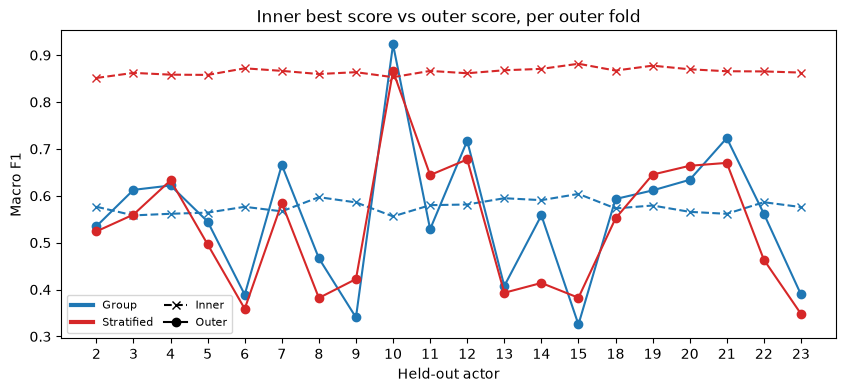

In [28]:
fig, ax = plt.subplots(figsize=(10, 4))
actors = per_fold_nested_group["held_out_actor"].astype(str)

for per_fold, name, color in [(per_fold_nested_group, "Group", "tab:blue"),
                              (per_fold_nested_strat, "Stratified", "tab:red")]:
    ax.plot(actors, per_fold["inner_best_score"], color=color, linestyle="--", marker="x")
    ax.plot(actors, per_fold["macro_f1"], color=color, marker="o")
    ax.plot([], [], color=color, linewidth=3, label=name)

ax.plot([], [], color="black", linestyle="--", marker="x", label="Inner")
ax.plot([], [], color="black", marker="o", label="Outer")

ax.set_xlabel("Held-out actor")
ax.set_ylabel("Macro F1")
ax.set_title("Inner best score vs outer score, per outer fold")
ax.legend(fontsize=8, loc="lower left", ncol=2, columnspacing=1)
plt.show()

### Answer 4.7

With `StratifiedKFold`, the inner folds ignore the actor: each of the 19 training actors has videos in both the inner training and the inner validation folds. This is the same leak as in 4.1, now inside the choice of C. The inner estimate jumps to 0.865 and it misses the outer score by 0.330.

This leak also changes the C value chosen. When the actor is known, a large C is better because the SVM can fit the details of each actor's face, and those details reappear in the inner validation videos of the same actor. That is why `C = 100` is chosen in 18 of the 20 folds. On a new person those details are useless: the 4.5 curve already shows that `C = 100` is worse than `C = 1` under LOSO. The outer score therefore drops slightly (0.557 to 0.534), while the inner estimate is wrong by 0.33.\
The outer score is lower, compared to the `GroupKFold` approach, for 14 of the 20 held-out actors. The outer loop remains honest, since the held-out actor is never seen, so the damage shows up as a worse choice of C rather than a wrong final score.

Every other decision made with cross-validation in this project must split by actor. Any splitter that ignores the actor will always have the same problem, a biased estimate. It will consistently pick the option that memorises faces over the one that generalises to new faces, and it will report a score that never corresponds to the true performance on new data.

## 4.8 Nested LOSO (GroupKFold) with base Features Only

### Comparison Table (Base vs Base + Own Features)

In [29]:
X_base = feature_table_base.to_numpy()

per_fold_nested_base, predictions_nested_base = evl.nested_evaluation(
    X_base, y, groups, pipe_nested, param_grid, GroupKFold(n_splits=5))

pd.DataFrame({"30 base features": nested_summary(per_fold_nested_base),
              "55 features (base + own)": nested_summary(per_fold_nested_group)})

,30 base features,55 features (base + own)
C chosen (count of folds),{1: 20},"{1: 19, 10: 1}"
mean inner best score,0.5433,0.5768
outer macro F1 mean,0.5254,0.5575
outer macro F1 std,0.1338,0.146
outer accuracy mean,0.5592,0.5875


### Table for Conclusions

In [30]:
paired = pd.DataFrame({"held_out_actor": per_fold_nested_group["held_out_actor"],
                       "base_30": per_fold_nested_base["macro_f1"].values,
                       "all_55": per_fold_nested_group["macro_f1"].values})
paired["difference"] = paired["all_55"] - paired["base_30"]
diff = paired["difference"]

pd.DataFrame({"Values": pd.Series({"Macro F1 Mean Differences (55 - 30)": round(diff.mean(), 4),
                                   "STD of the Macro F1 Differences": round(diff.std(), 4),
                                   "Standard Error of the Mean Differences": round(diff.std() / np.sqrt(len(diff)), 4),
                                   "STD of Macro F1 over Folds (55 features)": round(paired["all_55"].std(), 4),
                                   "Actors Improved": int((diff > 0).sum()),
                                   "Wilcoxon signed-rank p-value": round(wilcoxon(paired["all_55"], paired["base_30"]).pvalue, 4)},
                                  dtype=object)})

,Values
Macro F1 Mean Differences (55 - 30),0.0321
STD of the Macro F1 Differences,0.1166
Standard Error of the Mean Differences,0.0261
STD of Macro F1 over Folds (55 features),0.146
Actors Improved,14
Wilcoxon signed-rank p-value,0.0759


### Visualisation of the Difference Between Macro F1 per Actor

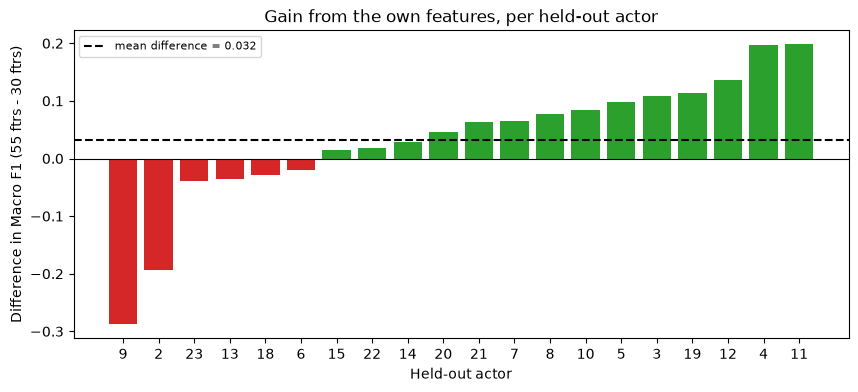

In [31]:
paired_sorted = paired.sort_values("difference")

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(paired_sorted["held_out_actor"].astype(str), paired_sorted["difference"],
              color=np.where(paired_sorted["difference"] > 0, "tab:green", "tab:red"))
ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(diff.mean(), color="black", linestyle="--", label=f"mean difference = {diff.mean():.3f}")
ax.set_xlabel("Held-out actor")
ax.set_ylabel("Difference in Macro F1 (55 ftrs - 30 ftrs)")
ax.set_title("Gain from the own features, per held-out actor")
ax.legend(fontsize=8)
plt.show()

### Emotions helped by own features

In [32]:
recall_features = pd.DataFrame({
    "30 base": recall_score(predictions_nested_base["y_true"], predictions_nested_base["y_pred"], labels=np.unique(y), average=None),
    "55 (base + own)": recall_score(predictions_nested_group["y_true"], predictions_nested_group["y_pred"], labels=np.unique(y), average=None)},
    index=labels_names)
recall_features["Gain"] = recall_features["55 (base + own)"] - recall_features["30 base"]
recall_features.sort_values("Gain", ascending=False).round(3)

,30 base,55 (base + own),Gain
sad,0.425,0.494,0.069
angry,0.656,0.706,0.050
happy,0.694,0.738,0.044
fearful,0.538,0.575,0.037
neutral,0.600,0.625,0.025
surprised,0.394,0.412,0.019
disgust,0.575,0.575,0.000
calm,0.612,0.594,-0.019


### Answer 4.8

The features of 3.2 raise the outer macro F1 by 0.032 on average and improve the score of 14 of the 20 held-out actors. The gains fall mostly where the own features were designed to act: 
- Sad (M8, lower lip to nose)
- Angry (M9, brow slope)
- Happy (M7, mouth corner to eye corner)
- Fearful (M11, brow shape)

Disgust, the target of M10 (upper lip to nose), does not change. Our hypothesis is that the upper lip moves too much with speech, making it difficult to isolate the raised lip of disgust.

**The difference is not larger than the variation between folds**\
The standard deviation of the macro F1 over folds is about 0.14, more than four times the gain. Because both runs test the same actors, the fairer comparison is paired, actor by actor. The differences have a standard deviation of 0.117, so the mean gain of 0.032 is barely noticeable when compared with its standard errors of 0.026. A Wilcoxon signed-rank test gives p = 0.076. 

**Conclusions about the own features**\
The own features very likely help a little, but with 20 actors the gain cannot be clearly told apart from the luck of which actors were tested. The 25 extra features are kept because the gain is consistent in direction and each one is justified by an expression as stated in section 3.2, not because the difference is proven.